# Audible Insights - Step 2: Exploratory Data Analysis (EDA)

In this notebook I explore the cleaned data and answer the EDA questions from the project document.

### Import libraries

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_style("whitegrid")

### Load the cleaned data

In [2]:
df = pd.read_csv("../data/cleaned_books.csv")
df["Genres"] = df["Genres"].fillna("")
df["Description"] = df["Description"].fillna("")
print(df.shape)
df.head()

(6063, 11)


,Book Name,Author,Rating,Number of Reviews,Price,Description,Listening Minutes,Overall Rank,Genres,Primary Genre,text
0,"""Don't You Know Who I Am?"": How to Stay Sane i...",Ramani S. Durvasula PhD,4.8,170,836,,NaN,NaN,,Unknown,"""don't you know who i am?"": how to stay sane i..."
1,#Girlboss,Sophia Amoruso,4.5,2272,615,"Penguin presents the unabridged downloadable, ...",NaN,NaN,,Unknown,#girlboss penguin presents the unabridged dow...
2,#TheRealCinderella: #BestFriendsForever Series...,Yesenia Vargas,4.3,179,586,,NaN,NaN,,Unknown,#therealcinderella: #bestfriendsforever series...
3,10 Bedtime Stories For Little Kids,div.,NaN,0,376,,NaN,NaN,,Unknown,10 bedtime stories for little kids
4,10 Essential Pieces of Literature,Khalil Gibran,NaN,0,32,,5264.0,759.0,Classic Literature|Classic Fiction,Classic Literature,10 essential pieces of literature classic lite...


In [3]:
df.describe()

,Rating,Number of Reviews,Price,Listening Minutes,Overall Rank
count,5482.000000,6063.000000,6063.000000,2096.000000,1975.000000
mean,4.456968,843.456045,925.598714,608.633588,2444.766076
std,0.350520,2410.206981,1551.147628,572.643208,3310.220906
min,1.000000,0.000000,0.000000,3.000000,1.000000
25%,4.300000,35.000000,501.000000,302.750000,721.500000
50%,4.500000,190.000000,683.000000,490.000000,2071.000000
75%,4.700000,664.000000,888.000000,744.000000,3455.000000
max,5.000000,70122.000000,18290.000000,7591.000000,29864.000000


## Q1. What are the most popular genres?

One book can have many genres, so I split the Genres column and count each genre.

In [4]:
genre_list = []
for g in df["Genres"]:
    if g != "":
        for genre in g.split("|"):
            genre_list.append(genre)

genre_counts = pd.Series(genre_list).value_counts()
print("Total unique genres:", len(genre_counts))
genre_counts.head(15)

Total unique genres: 876


Personal Success                    200
Personal Development & Self-Help    156
Analysis & Strategy                 121
Textbooks & Study Guides            119
Classic Literature                   85
Leadership                           77
Contemporary Fiction                 74
Literary Fiction                     70
Crime, Thriller & Mystery            63
Biographies & Autobiographies        59
Historical Fiction                   55
Classic Fiction                      51
Psychology                           48
Romance                              48
Contemporary Romance                 47
Name: count, dtype: int64

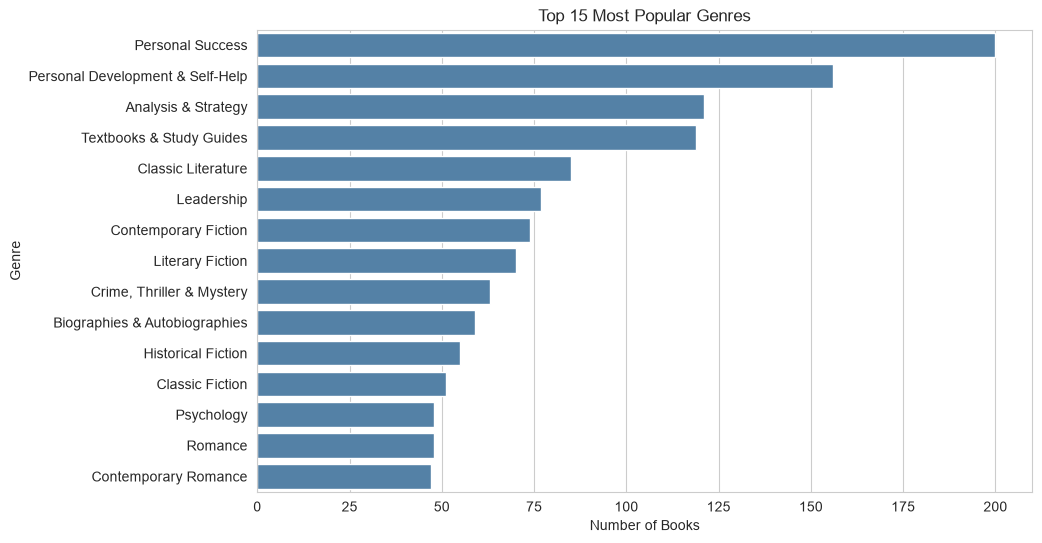

In [5]:
plt.figure(figsize=(10, 6))
sns.barplot(x=genre_counts.head(15).values, y=genre_counts.head(15).index, color="steelblue")
plt.title("Top 15 Most Popular Genres")
plt.xlabel("Number of Books")
plt.ylabel("Genre")
plt.show()

**Observation:** Personal Success and Personal Development & Self-Help are the most common genres, followed by business genres (Analysis & Strategy, Leadership). Fiction genres such as Classic Literature, Contemporary Fiction and Literary Fiction are also common.

### Most common authors

In [6]:
top_authors = df["Author"].value_counts().head(15)
top_authors

Author
Harvard Business Review         32
OSHO                            32
Devdutt Pattanaik               29
Ruskin Bond                     28
Innovative Language Learning    28
Rick Riordan                    26
Agatha Christie                 24
Brian Tracy                     22
Robin Sharma                    20
Roald Dahl                      20
Georgette Heyer                 20
Shanaya Taneja                  19
Gertrude Chandler Warner        19
DK                              18
Sidney Sheldon                  17
Name: count, dtype: int64

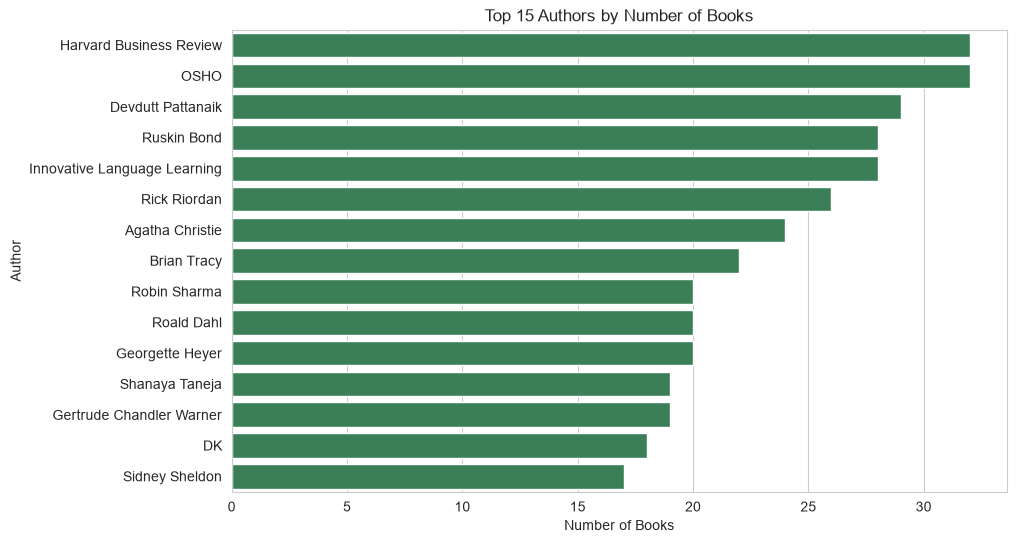

In [7]:
plt.figure(figsize=(10, 6))
sns.barplot(x=top_authors.values, y=top_authors.index, color="seagreen")
plt.title("Top 15 Authors by Number of Books")
plt.xlabel("Number of Books")
plt.ylabel("Author")
plt.show()

## Q2. Which authors have the highest-rated books?

I only take authors with **at least 3 rated books**, because an author with one 5-star book is not a fair comparison.

In [8]:
rated = df[df["Rating"].notnull()]

author_stats = rated.groupby("Author").agg(
    books=("Rating", "count"),
    avg_rating=("Rating", "mean"),
    total_reviews=("Number of Reviews", "sum")
)

author_stats = author_stats[author_stats["books"] >= 3]
top_rated_authors = author_stats.sort_values(by=["avg_rating", "total_reviews"], ascending=False).head(10)
top_rated_authors

,books,avg_rating,total_reviews
Author,,,
Tracey West,3,4.866667,1633
Tui T. Sutherland,9,4.855556,10414
Anodea Judith,3,4.800000,1567
Joyce Meyer,3,4.800000,1178
Bill Johnson,3,4.800000,969
Watchman Nee,3,4.800000,819
Alan Watts,5,4.800000,349
J. Krishnamurti,3,4.800000,36
Norman Bridwell,5,4.780000,1209


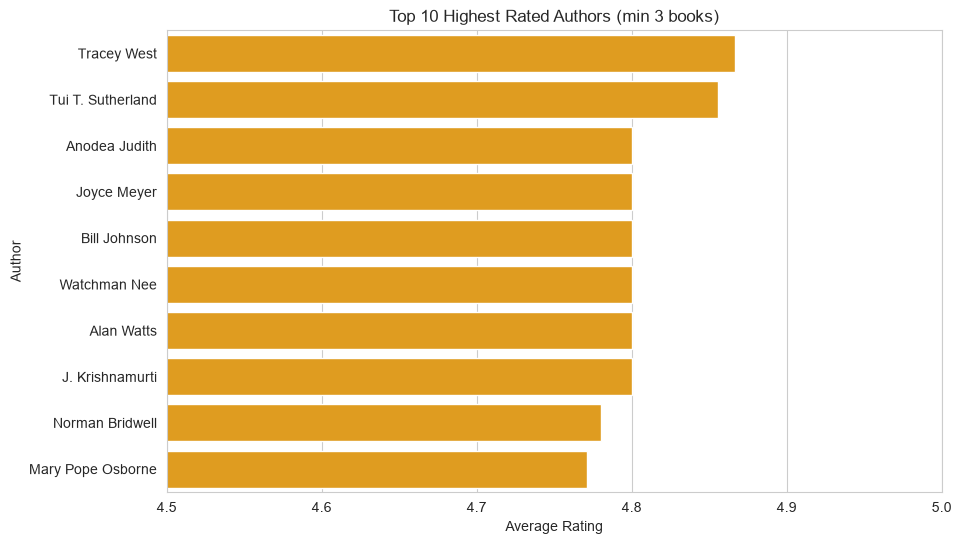

In [9]:
plt.figure(figsize=(10, 6))
sns.barplot(x=top_rated_authors["avg_rating"], y=top_rated_authors.index, color="orange")
plt.title("Top 10 Highest Rated Authors (min 3 books)")
plt.xlabel("Average Rating")
plt.xlim(4.5, 5)
plt.show()

**Observation:** Tui T. Sutherland (9 books, avg 4.86) stands out because she has many books and a very high rating. Children's authors (Mary Pope Osborne, Norman Bridwell) and spiritual authors (Alan Watts, J. Krishnamurti) also rate very high.

## Q3. What is the average rating distribution?

In [10]:
print("Average rating:", round(rated["Rating"].mean(), 2))
print("Median rating:", rated["Rating"].median())
print("Books not rated:", df["Rating"].isnull().sum())

Average rating: 4.46
Median rating: 4.5
Books not rated: 581


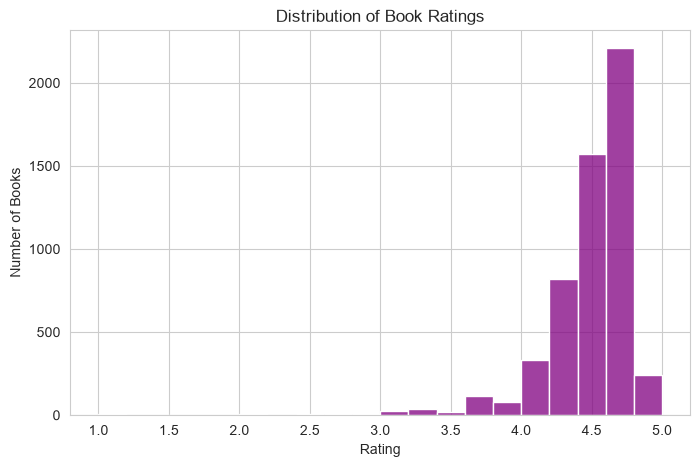

In [11]:
plt.figure(figsize=(8, 5))
sns.histplot(rated["Rating"], bins=20, color="purple")
plt.title("Distribution of Book Ratings")
plt.xlabel("Rating")
plt.ylabel("Number of Books")
plt.show()

In [12]:
rating_groups = pd.cut(rated["Rating"], bins=[0, 3, 3.5, 4, 4.5, 5])
rating_groups.value_counts().sort_index()

Rating
(0.0, 3.0]      51
(3.0, 3.5]      63
(3.5, 4.0]     334
(4.0, 4.5]    2588
(4.5, 5.0]    2446
Name: count, dtype: int64

**Observation:** Most books are rated between 4.0 and 5.0 (average about 4.46). Very few books are below 3.5, so the ratings are **left skewed**. This means a rating alone is not enough to separate good and bad books, and the number of reviews is also important.

## Q4. Are there trends in publication years?

The datasets **do not have a publication year column**, so this question cannot be answered directly.
Instead I check two related things:
- the overall Audible rank (popularity)
- listening time (length of the book)

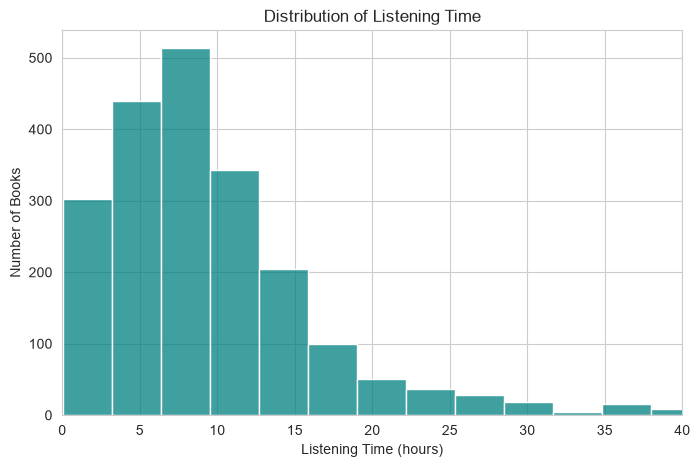

Average listening time (hours): 10.1


In [13]:
plt.figure(figsize=(8, 5))
sns.histplot(df["Listening Minutes"].dropna() / 60, bins=40, color="teal")
plt.title("Distribution of Listening Time")
plt.xlabel("Listening Time (hours)")
plt.ylabel("Number of Books")
plt.xlim(0, 40)
plt.show()

print("Average listening time (hours):", round(df["Listening Minutes"].mean() / 60, 1))

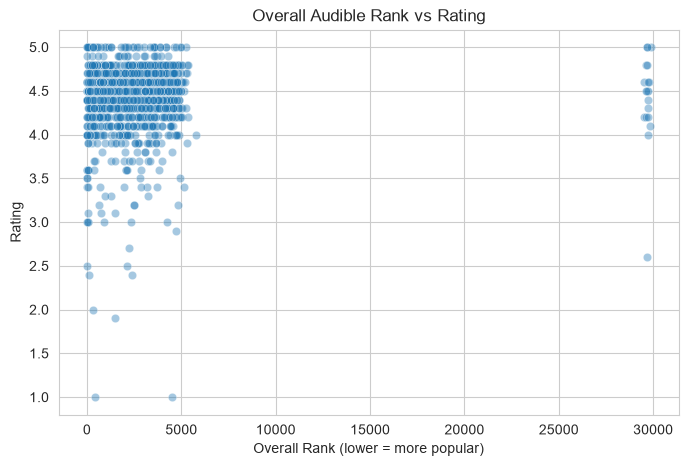

In [14]:
# Does popularity rank relate to rating?
ranked = df[df["Overall Rank"].notnull() & df["Rating"].notnull()]
plt.figure(figsize=(8, 5))
sns.scatterplot(x=ranked["Overall Rank"], y=ranked["Rating"], alpha=0.4)
plt.title("Overall Audible Rank vs Rating")
plt.xlabel("Overall Rank (lower = more popular)")
plt.ylabel("Rating")
plt.show()

**Observation:** Publication year is not available. Most audiobooks are between 5 and 15 hours long (average about 10 hours). Popular books (low rank number) do not have clearly higher ratings, so popularity and quality are different things.

## Q5. How do ratings vary with the number of reviews?

In [15]:
rated = rated.copy()
rated["Review Group"] = pd.cut(rated["Number of Reviews"],
                               bins=[0, 10, 100, 1000, 10000, 100000],
                               labels=["1-10", "11-100", "101-1000", "1001-10000", "10000+"])

rated.groupby("Review Group", observed=True)["Rating"].agg(["count", "mean", "std"])

,count,mean,std
Review Group,,,
1-10,438,4.268265,0.837246
11-100,1323,4.377173,0.342910
101-1000,2607,4.498082,0.225478
1001-10000,1052,4.530608,0.201031
10000+,62,4.514516,0.195730


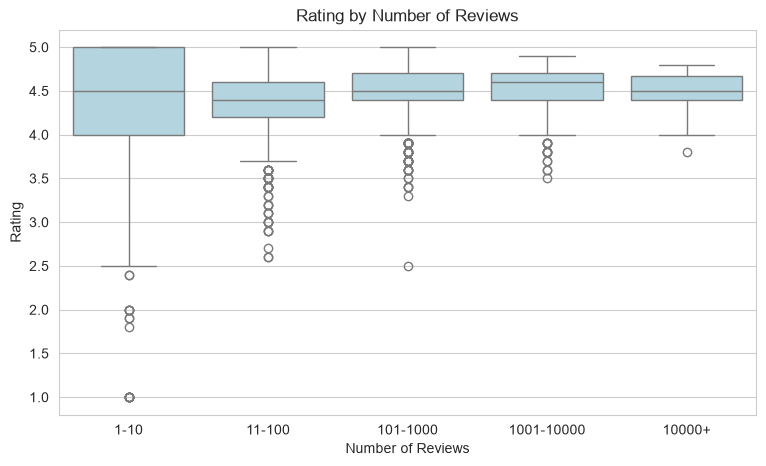

In [16]:
plt.figure(figsize=(9, 5))
sns.boxplot(x="Review Group", y="Rating", data=rated, color="lightblue")
plt.title("Rating by Number of Reviews")
plt.xlabel("Number of Reviews")
plt.ylabel("Rating")
plt.show()

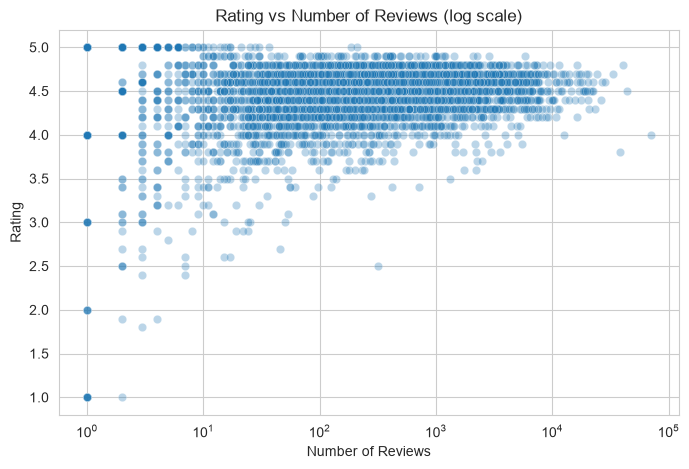

In [17]:
plt.figure(figsize=(8, 5))
sns.scatterplot(x=rated["Number of Reviews"], y=rated["Rating"], alpha=0.3)
plt.xscale("log")
plt.title("Rating vs Number of Reviews (log scale)")
plt.show()

**Observation:** Books with very few reviews (1-10) have the most varied ratings, from 1 to 5. As the number of reviews grows, the ratings become more stable around 4.5. So a rating backed by more reviews is more reliable.

## Correlation heatmap

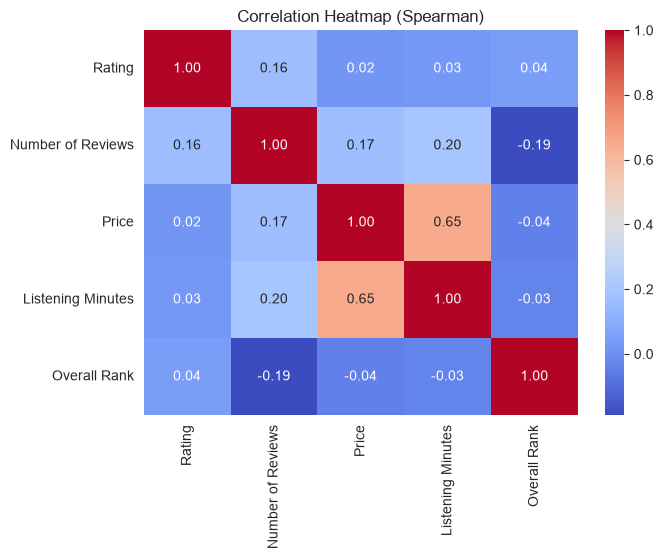

In [18]:
num_cols = ["Rating", "Number of Reviews", "Price", "Listening Minutes", "Overall Rank"]
corr = df[num_cols].corr(method="spearman")

plt.figure(figsize=(7, 5))
sns.heatmap(corr, annot=True, cmap="coolwarm", fmt=".2f")
plt.title("Correlation Heatmap (Spearman)")
plt.show()

I used **Spearman** correlation because reviews and price have a few very large values (outliers).

**Observation:**
- Price and listening time are strongly related (longer books cost more)
- Rating has only a weak relation with the number of reviews
- Rating is almost unrelated to price

## Price analysis

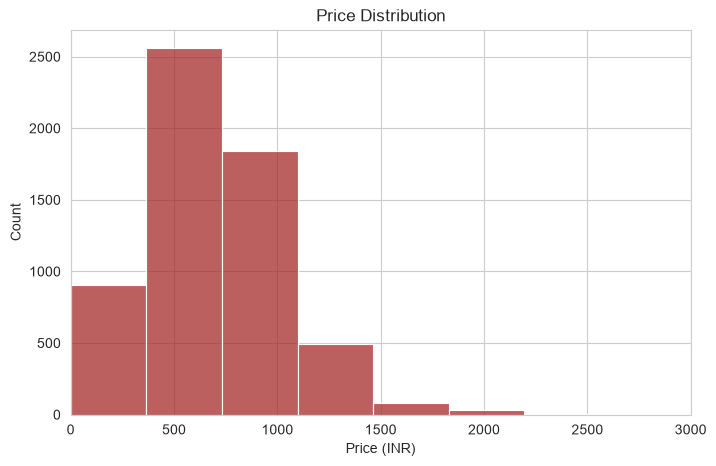

Median price: 683.0
Free books: 103


In [19]:
plt.figure(figsize=(8, 5))
sns.histplot(df["Price"], bins=50, color="brown")
plt.xlim(0, 3000)
plt.title("Price Distribution")
plt.xlabel("Price (INR)")
plt.show()

print("Median price:", df["Price"].median())
print("Free books:", (df["Price"] == 0).sum())

## Average rating by genre

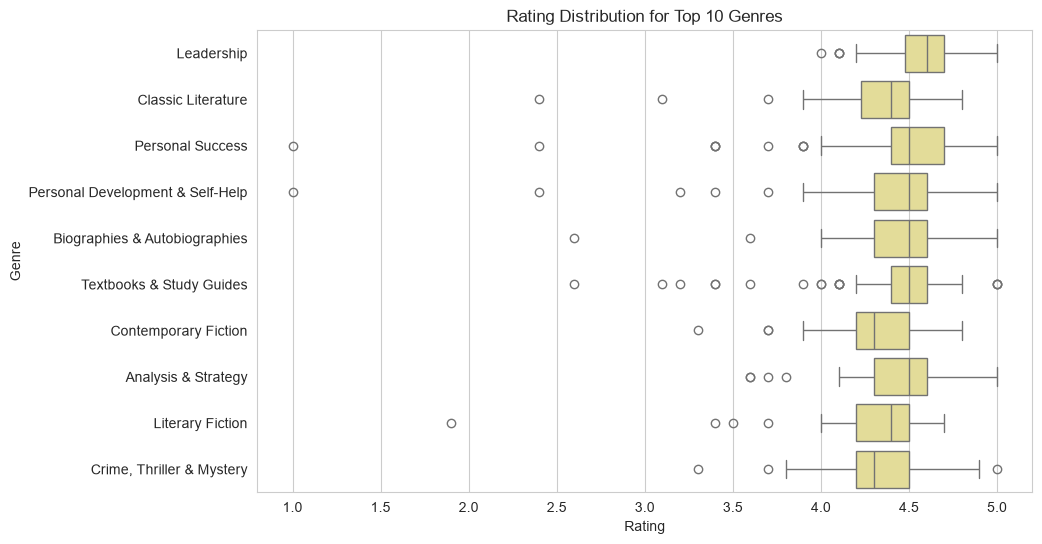

In [20]:
genre_rows = []
for i, row in rated.iterrows():
    if row["Genres"] != "":
        for genre in row["Genres"].split("|"):
            genre_rows.append([genre, row["Rating"]])

genre_df = pd.DataFrame(genre_rows, columns=["Genre", "Rating"])
top_genres = genre_counts.head(10).index
genre_df = genre_df[genre_df["Genre"].isin(top_genres)]

plt.figure(figsize=(10, 6))
sns.boxplot(x="Rating", y="Genre", data=genre_df, color="khaki")
plt.title("Rating Distribution for Top 10 Genres")
plt.show()

## Hidden gems (preview)

Books that are highly rated but have few reviews. These will be used later in the app.

In [21]:
hidden_gems = rated[(rated["Rating"] >= 4.7) & (rated["Number of Reviews"] >= 5) & (rated["Number of Reviews"] <= 50)]
hidden_gems = hidden_gems.sort_values(by="Rating", ascending=False)
print("Number of hidden gems:", len(hidden_gems))
hidden_gems[["Book Name", "Author", "Rating", "Number of Reviews", "Primary Genre"]].head(10)

Number of hidden gems: 217


,Book Name,Author,Rating,Number of Reviews,Primary Genre
4312,The Dungeon of Doom: Hank the Cowdog,John R. Erickson,5.0,8,Unknown
4060,The Book of Esports: The Definitive Guide to C...,William Collis,5.0,25,Unknown
1758,HBR's 10 Must Reads on Managing in a Downturn:...,Harvard Business Review,5.0,6,Unknown
3695,Stop Making Sense: The Art of Inspiring Anybody,Michael J. Fanuele,5.0,28,Unknown
1745,HBR Guide to Making Better Decisions: HBR Insi...,Harvard Business Review,5.0,5,Unknown
4969,The Original Be Here Now Talks,Ram Dass,5.0,5,Unknown
3996,The Beasts of Tarzan,Edgar Rice Burroughs,5.0,9,Unknown
910,Coming Home to Yourself: A Meditator's Guide t...,Osho,5.0,16,Meditation
1570,Geronimo Stilton #15 and #16,Geronimo Stilton,5.0,6,Unknown
1538,From Mindfulness to Insight: Meditations to Re...,Rob Nairn,5.0,9,Unknown


## EDA Summary

1. **Popular genres:** Personal Success, Self-Help and business books are the most common
2. **Top authors:** Tui T. Sutherland, Mary Pope Osborne and Alan Watts have consistently high ratings
3. **Ratings:** most books are rated 4.0-5.0 (average about 4.46), so ratings are left skewed
4. **Publication year:** not available in the dataset
5. **Ratings vs reviews:** books with few reviews have unreliable ratings, while books with many reviews settle around 4.5
6. **Price** is strongly related to listening time, but not to rating

These findings will help in building the recommendation system. For example, I'll combine rating with the number of reviews instead of using rating alone.